# Telco Customer Churn - Exploratory Data Analysis, Visualization & Deep Learning (MLP)

**Course:** U21ADP05 - Exploratory Data Analysis and Visualization  |  **Assignment II (Case Study)**
**Student:** Prashant Sharma Dhungana | **Roll No:** 24AD130 | **Dept:** AI & DS (AD-B) | **Year:** III

**Problem:** A telecom company loses revenue when customers leave (*churn*). Winning a new customer costs far more than keeping an existing one, so we want to (1) understand *why* customers churn and (2) predict *who* is likely to churn so the company can act early.

**Dataset:** IBM Telco Customer Churn (Kaggle, `blastchar/telco-customer-churn`) - 7,043 customers, 21 fields.

**Flow:** Acquire -> Parse -> Filter -> Mine -> Represent -> Refine -> Interact (the 7 stages of visualization), followed by an MLP model, evaluation charts, and conclusions.

> Run order: place the CSV in `data/` and run all cells top to bottom (about 2-3 minutes).

In [1]:
# ---------- 0. Imports & settings ----------
import os, json, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, precision_recall_curve)
from sklearn.utils.class_weight import compute_class_weight

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold"})
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
RESULTS = {}          # numbers collected here are reused in the written report

def savefig(name):
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()


I0000 00:00:1791892342.171293    8256 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791892343.533330    8256 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# ---------- 1. Data loading (Stage 1: Acquire, Stage 2: Parse) ----------
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape:", df.shape)
display(df.head())
df.info()


Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Stage 1-2 (Acquire & Parse).** The file has 7,043 rows and 21 columns (3 numeric, 17 categorical incl. the target `Churn`, plus `customerID`). Note that `TotalCharges` was read as *text* - something is wrong with its values, which is handled next.

In [3]:
# ---------- 2. Data quality checks (Stage 3: Filter) ----------
print("Duplicate rows (all columns):", df.duplicated().sum())
print("Duplicate customerIDs     :", df["customerID"].duplicated().sum())

# TotalCharges is stored as text because some cells are blank spaces
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("\nMissing values after numeric conversion:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nRows with missing TotalCharges (check tenure):")
display(df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

# These customers have tenure = 0 (brand new, not billed yet) -> TotalCharges = 0 is the logical value
df.loc[df["TotalCharges"].isna(), "TotalCharges"] = 0.0

# SeniorCitizen is 0/1 -> make it a readable category like the other Yes/No columns
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
RESULTS["n_rows"], RESULTS["n_cols"] = int(df.shape[0]), int(df.shape[1])
RESULTS["churn_rate"] = float((df["Churn"] == "Yes").mean())


Duplicate rows (all columns): 0
Duplicate customerIDs     : 0

Missing values after numeric conversion:
TotalCharges    11
dtype: int64

Rows with missing TotalCharges (check tenure):


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


**Stage 3 (Filter) - data quality.** No duplicate rows or IDs. `TotalCharges` had 11 blank cells. All 11 customers have `tenure = 0` (they joined this month and have not been billed yet), so the correct value is **0**, not a mean/median imputation.

In [4]:
# ---------- 3. Basic statistics ----------
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID", "Churn"]]
print(f"{len(num_cols)} numeric features, {len(cat_cols)} categorical features (+ customerID, Churn target)")
desc = df[num_cols].describe().T
desc["skewness"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurt()
display(desc.round(2))
RESULTS["describe"] = desc.round(2).to_dict()
print("\nTarget distribution:")
print(df["Churn"].value_counts(), "\n", df["Churn"].value_counts(normalize=True).round(3))


3 numeric features, 16 categorical features (+ customerID, Churn target)


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00,0.24,-1.39
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75,-0.22,-1.26
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80,0.96,-0.23



Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64 
 Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


**Basic statistics.** Average tenure is 32 months and the average monthly bill is about $65. `TotalCharges` is right-skewed (skew 0.96) because it grows with tenure. The target is **imbalanced: 26.5% churn vs 73.5% stay**, so plain accuracy would be misleading, and we use class weights, recall, F1 and AUC later.

In [5]:
# ---------- 4. Outlier detection (IQR rule) ----------
out_rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    out_rows.append({"feature": c, "lower_fence": round(lo, 2), "upper_fence": round(hi, 2), "n_outliers": n_out})
outliers = pd.DataFrame(out_rows); display(outliers)
RESULTS["outliers"] = outliers.to_dict("records")
# Decision: all values are valid business values (no negative/impossible numbers), so we KEEP them.


,feature,lower_fence,upper_fence,n_outliers
0,tenure,-60.00,124.00,0
1,MonthlyCharges,-46.02,171.38,0
2,TotalCharges,-4683.52,8868.67,0


**Outliers.** Using the IQR (1.5 x IQR) rule, none of the three numeric columns has a value outside the fences, and all values are plausible (tenure 0-72 months, charges $18-$119). Nothing is removed. (The dots seen later in the `TotalCharges` boxplot for churners are just the long right tail of one group, not data errors.)

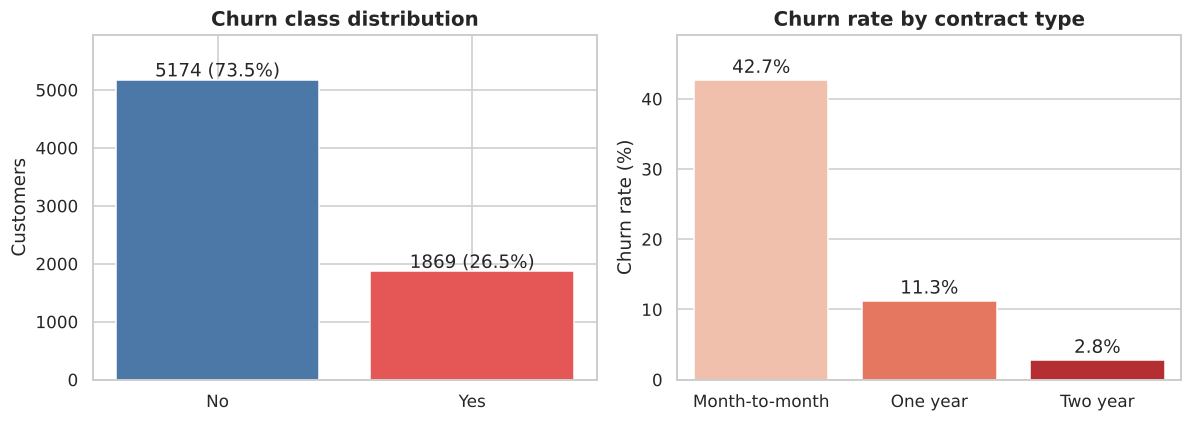

In [6]:
# ---------- VISUAL 1: Target distribution (Bernoulli) + categorical churn rates ----------
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cnt = df["Churn"].value_counts()
ax[0].bar(cnt.index, cnt.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(cnt.values): ax[0].text(i, v + 60, f"{v} ({v/len(df):.1%})", ha="center")
ax[0].set(title="Churn class distribution", ylabel="Customers", ylim=(0, cnt.max() * 1.15))
order = ["Month-to-month", "One year", "Two year"]
rate = df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).reindex(order)
sns.barplot(x=rate.index, y=rate.values * 100, ax=ax[1], palette="Reds")
for i, v in enumerate(rate.values): ax[1].text(i, v * 100 + 1, f"{v:.1%}", ha="center")
ax[1].set(title="Churn rate by contract type", ylabel="Churn rate (%)", xlabel="", ylim=(0, rate.max() * 100 * 1.15))
savefig("01_target_and_contract")
RESULTS["churn_by_contract"] = rate.round(4).to_dict()


### Visual 1 - Target distribution and churn by contract (bar charts)
- **What it shows:** how many customers churned, and the churn rate for each contract type.
- **Why:** to understand class balance (affects modelling) and to test the most obvious business driver.
- **Insight:** 26.5% of customers churn (imbalanced data). Churn is strongly tied to contract length: **42.7%** for month-to-month vs **11.3%** for one-year and only **2.8%** for two-year contracts.

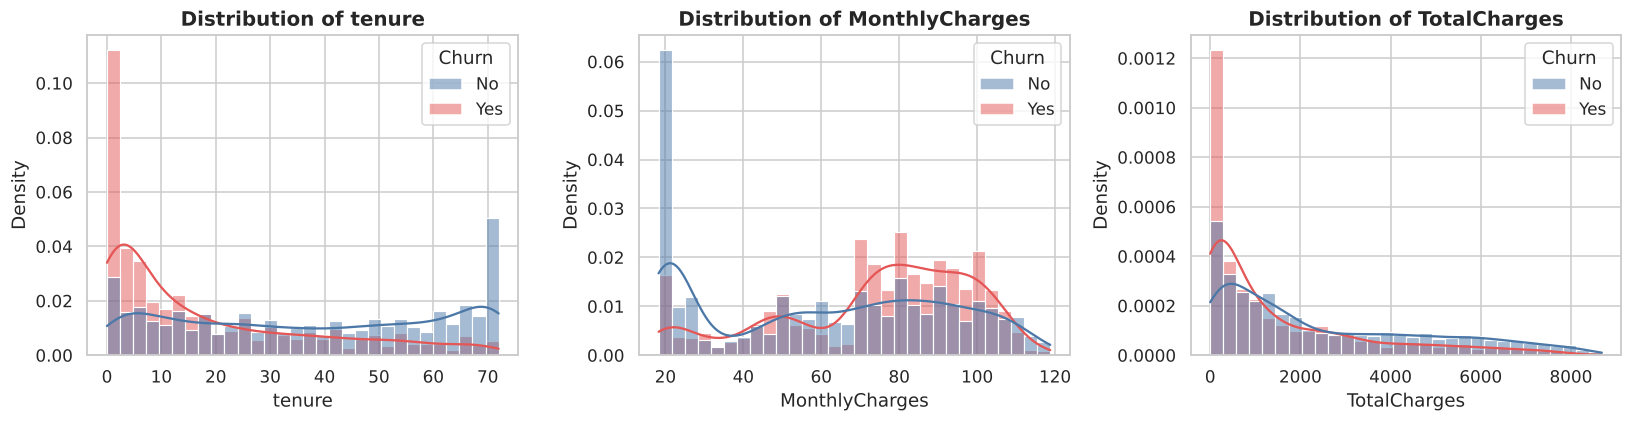

tenure | mean churn=Yes: 18.0 | mean churn=No: 37.6
MonthlyCharges | mean churn=Yes: 74.4 | mean churn=No: 61.3
TotalCharges | mean churn=Yes: 1531.8 | mean churn=No: 2549.9


In [7]:
# ---------- VISUAL 2: Histograms + KDE of numeric features split by churn ----------
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, num_cols):
    sns.histplot(data=df, x=c, hue="Churn", kde=True, stat="density", common_norm=False,
                 palette={"No": "#4C78A8", "Yes": "#E45756"}, ax=a, bins=30)
    a.set(title=f"Distribution of {c}", xlabel=c)
savefig("02_numeric_histograms")
for c in num_cols:
    print(c, "| mean churn=Yes: %.1f | mean churn=No: %.1f" % (df.loc[df.Churn=="Yes", c].mean(), df.loc[df.Churn=="No", c].mean()))
RESULTS["means_by_churn"] = {c: {"Yes": float(df.loc[df.Churn=="Yes", c].mean()), "No": float(df.loc[df.Churn=="No", c].mean())} for c in num_cols}


### Visual 2 - Histograms with KDE, split by churn
- **What it shows:** the distribution of `tenure`, `MonthlyCharges` and `TotalCharges` for churners vs non-churners.
- **Why:** to see the shape of each numeric variable and where the two groups differ.
- **Insight:** churners are concentrated at **very low tenure** (mean 18 vs 38 months) and **higher monthly charges** (mean $74.4 vs $61.3). Non-churners show a spike at 72 months (long-term loyal customers). `MonthlyCharges` has a spike near $20 (basic phone-only plan, rarely churns).

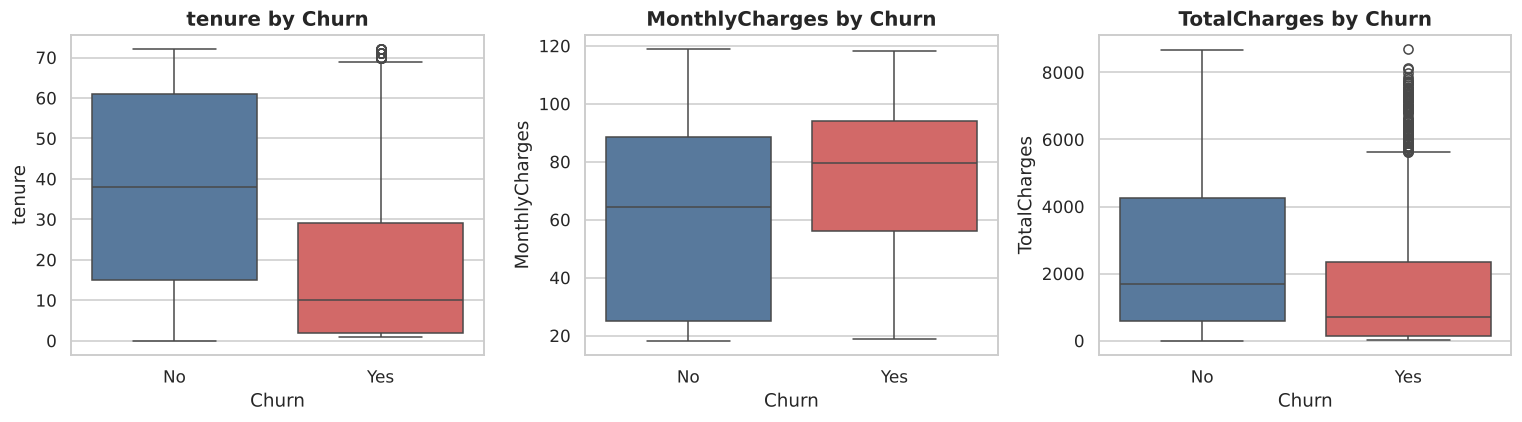

In [8]:
# ---------- VISUAL 3: Boxplots of numeric features by churn (outlier view) ----------
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, c in zip(ax, num_cols):
    sns.boxplot(data=df, x="Churn", y=c, palette={"No": "#4C78A8", "Yes": "#E45756"}, ax=a)
    a.set(title=f"{c} by Churn")
savefig("03_boxplots")


### Visual 3 - Boxplots by churn
- **What it shows:** median, spread and outliers of each numeric variable for the two classes.
- **Why:** boxplots compare groups compactly and reveal outliers.
- **Insight:** median tenure of churners is about 10 months vs 38 for stayers; churners have a higher median monthly bill (~$80 vs ~$64). Churners' `TotalCharges` is low because they leave early.

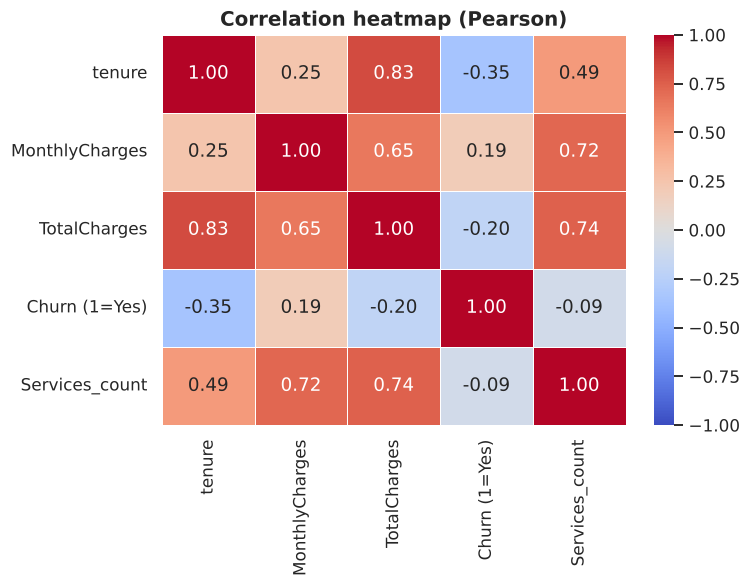

tenure           -0.352
MonthlyCharges    0.193
TotalCharges     -0.198
Churn (1=Yes)     1.000
Services_count   -0.088
Name: Churn (1=Yes), dtype: float64

In [9]:
# ---------- VISUAL 4: Correlation heatmap (numeric + encoded target) ----------
tmp = df[num_cols].copy(); tmp["Churn (1=Yes)"] = (df["Churn"] == "Yes").astype(int)
tmp["Services_count"] = (df[["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]] == "Yes").sum(axis=1)
corr = tmp.corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=.5)
plt.title("Correlation heatmap (Pearson)")
savefig("04_correlation_heatmap")
display(corr["Churn (1=Yes)"].round(3))
RESULTS["corr_with_churn"] = corr["Churn (1=Yes)"].round(3).to_dict()
RESULTS["corr_tenure_total"] = float(corr.loc["tenure", "TotalCharges"])


### Visual 4 - Correlation heatmap
- **What it shows:** Pearson correlation between numeric features, the number of add-on services, and churn.
- **Why:** to spot relationships and multicollinearity before modelling.
- **Insight:** `tenure` has the strongest correlation with churn (**-0.35**), then `TotalCharges` (-0.20) and `MonthlyCharges` (+0.19). `tenure` and `TotalCharges` are highly correlated (**0.83**) because total = monthly x months, so they carry overlapping information.

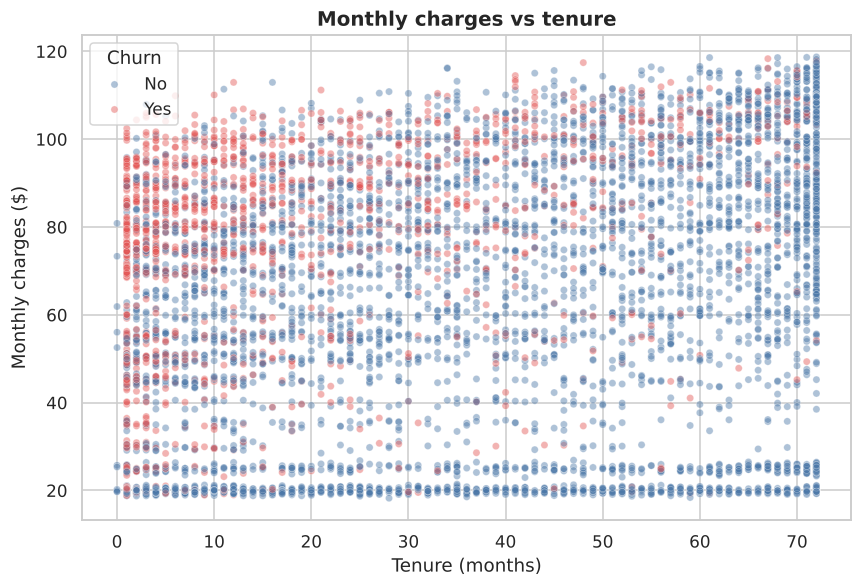

In [10]:
# ---------- VISUAL 5: Scatter plot - MonthlyCharges vs tenure coloured by churn ----------
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=df, x="tenure", y="MonthlyCharges", hue="Churn", alpha=.45, s=22,
                palette={"No": "#4C78A8", "Yes": "#E45756"})
plt.title("Monthly charges vs tenure"); plt.xlabel("Tenure (months)"); plt.ylabel("Monthly charges ($)")
savefig("05_scatter_tenure_monthly")


### Visual 5 - Scatter plot: tenure vs monthly charges
- **What it shows:** each customer as a point, coloured by churn.
- **Why:** to see two variables together and find the "risky" region.
- **Insight:** red points (churn) cluster in the **top-left**: new customers (low tenure) on **high monthly plans ($70-$105)**. The bottom-right (long tenure) is almost entirely blue.

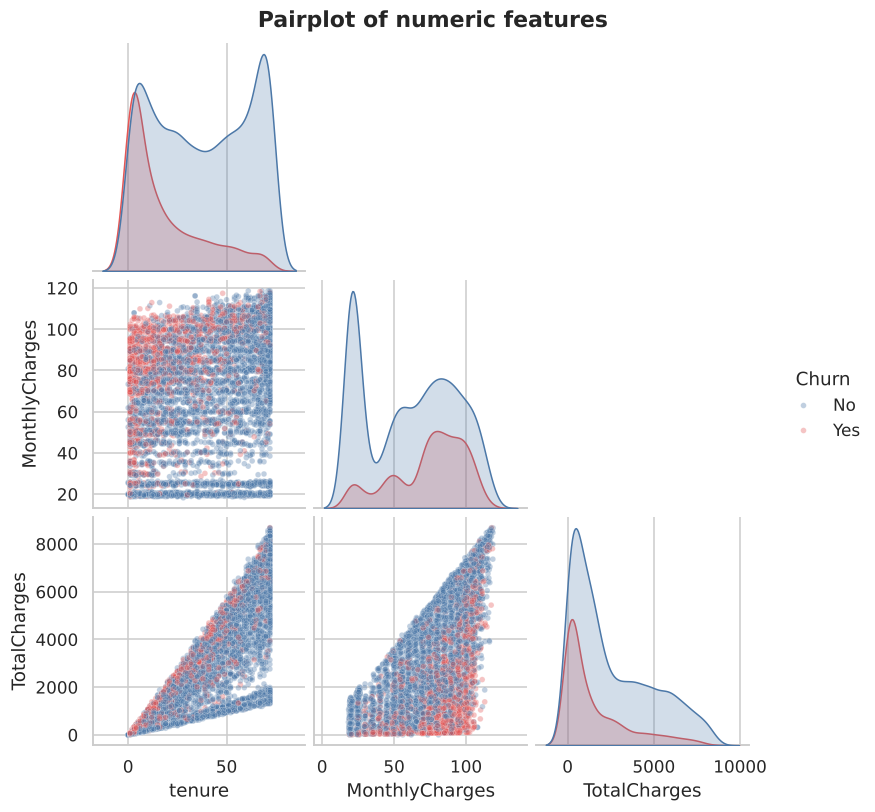

In [11]:
# ---------- VISUAL 6: Pairplot ----------
pp = sns.pairplot(df[num_cols + ["Churn"]], hue="Churn", palette={"No": "#4C78A8", "Yes": "#E45756"},
                  corner=True, plot_kws={"alpha": .35, "s": 14}, height=2.4)
pp.fig.suptitle("Pairplot of numeric features", y=1.02, fontweight="bold")
pp.savefig(f"{FIG_DIR}/06_pairplot.png", dpi=150, bbox_inches="tight"); plt.show()


### Visual 6 - Pairplot
- **What it shows:** all pairwise scatter plots and the marginal distribution of each numeric variable by churn class.
- **Why:** gives a multivariate overview in one figure.
- **Insight:** confirms the linear-looking `tenure`-`TotalCharges` relationship and shows churners are separable mainly along the tenure axis.

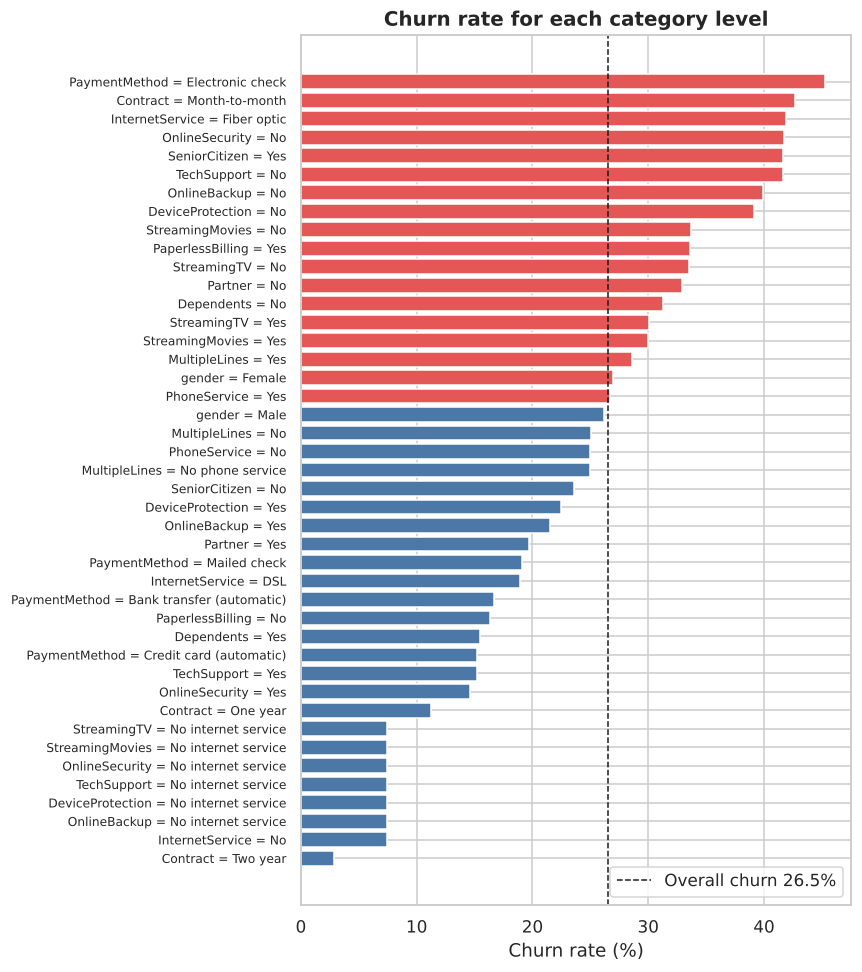

In [12]:
# ---------- VISUAL 7: Churn rate by every categorical feature (ranked) ----------
rows = []
for c in cat_cols:
    for lvl, s in df.groupby(c)["Churn"]:
        rows.append({"feature": c, "level": lvl, "label": f"{c} = {lvl}", "churn_rate": (s == "Yes").mean(), "n": len(s)})
cr = pd.DataFrame(rows).sort_values("churn_rate")
plt.figure(figsize=(8, 9))
colors = ["#E45756" if v > RESULTS["churn_rate"] else "#4C78A8" for v in cr["churn_rate"]]
plt.barh(cr["label"], cr["churn_rate"] * 100, color=colors)
plt.axvline(RESULTS["churn_rate"] * 100, color="k", ls="--", lw=1, label=f"Overall churn {RESULTS['churn_rate']:.1%}")
plt.xlabel("Churn rate (%)"); plt.title("Churn rate for each category level"); plt.legend(loc="lower right")
plt.yticks(fontsize=8)
savefig("07_churn_rate_by_category")
RESULTS["top_levels"] = cr.tail(5)[["label", "churn_rate"]].round(3).to_dict("records")
RESULTS["bottom_levels"] = cr.head(5)[["label", "churn_rate"]].round(3).to_dict("records")


### Visual 7 - Churn rate for every category level (ranked)
- **What it shows:** churn rate of each level of every categorical feature, compared with the overall 26.5% (dashed line).
- **Why:** quickly identify which customer segments are high-risk.
- **Insight:** the riskiest segments are **month-to-month contracts (42.7%)**, **electronic-check payers (45.3%)**, **fibre-optic internet (41.9%)** and customers **without Online Security / Tech Support (~42%)**. Safest: two-year contracts (2.8%), customers with no internet (7.4%). Senior citizens churn at 41.7% vs 23.6%.

In [ ]:
# ---------- VISUAL 8 (Stage 7: Interact): interactive Plotly chart, saved as HTML ----------
fig = px.scatter(df, x="tenure", y="MonthlyCharges", color="Churn", symbol="Contract", opacity=.6,
                 hover_data=["InternetService", "PaymentMethod", "TotalCharges"],
                 color_discrete_map={"No": "#4C78A8", "Yes": "#E45756"},
                 title="Interactive: tenure vs monthly charges (hover, zoom, filter by legend)")
fig.write_html(f"{FIG_DIR}/08_interactive_scatter.html")
print(f"Interactive chart saved to {FIG_DIR}/08_interactive_scatter.html")

### Visual 8 - Interactive Plotly chart (Stage 7: Interact)
Saved as `figures/08_interactive_scatter.html` - open it in a browser to hover for details, zoom, and click the legend to hide/show groups. Marker shape shows the contract type, so you can check which contract types the churners (red) are on.

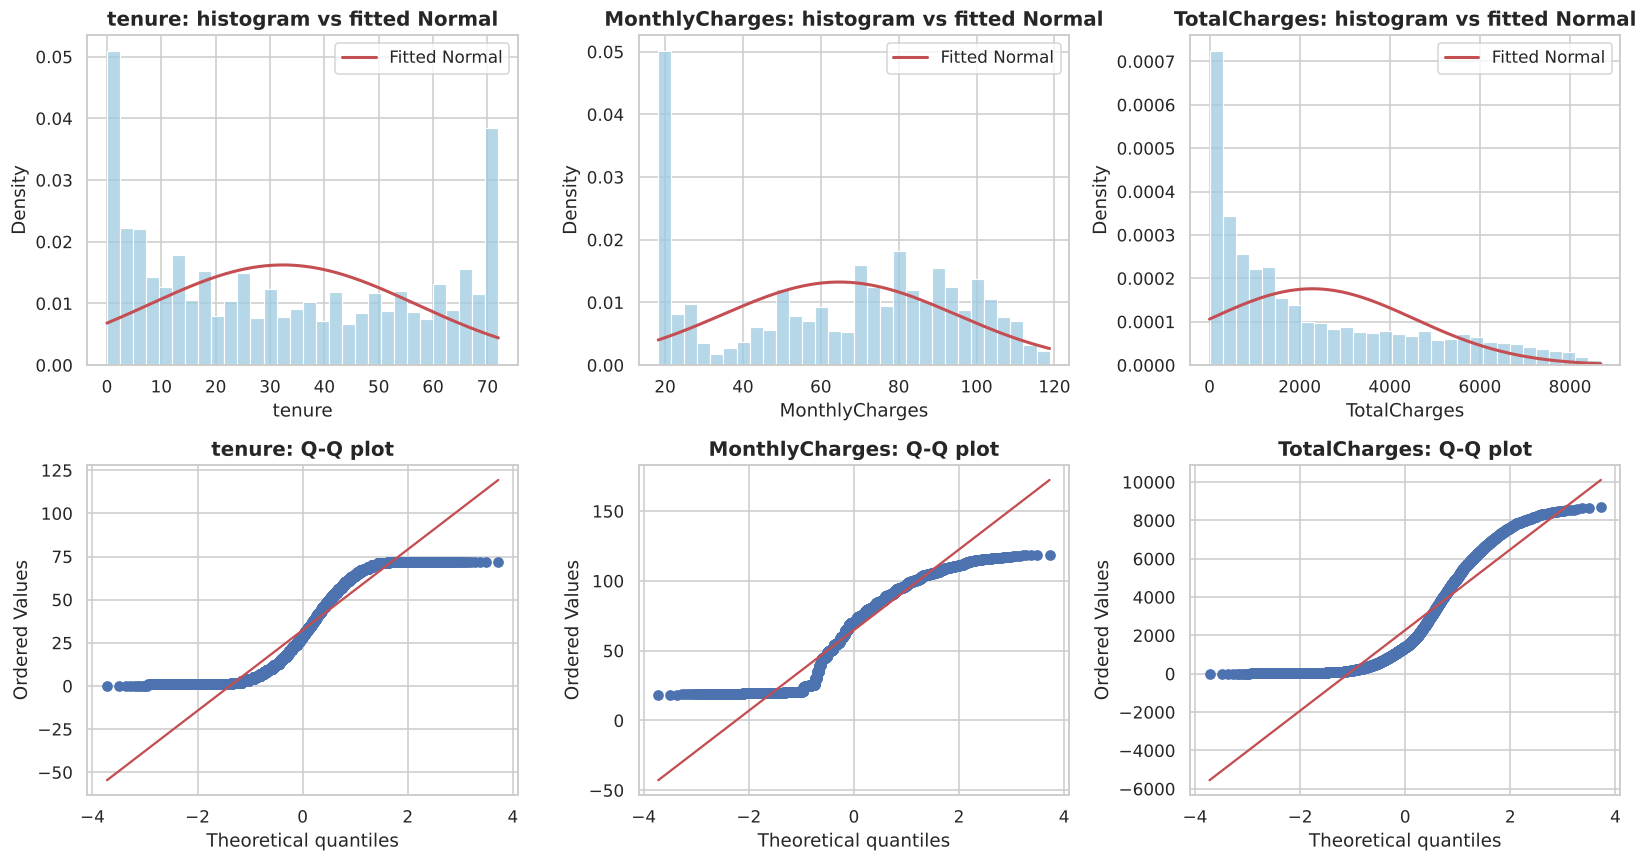

,feature,skew,excess_kurtosis,D'Agostino K2,p_value,normal?
0,tenure,0.240,-1.387,76258.5,0.000000e+00,No
1,MonthlyCharges,-0.221,-1.257,11419.5,0.000000e+00,No
2,TotalCharges,0.963,-0.229,808.6,2.604914e-176,No


In [14]:
# ---------- 5. Univariate / distribution analysis (statistical) ----------
# Continuous: normality tests, skewness, Q-Q plots, fitted normal curve
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
norm_rows = []
for j, c in enumerate(num_cols):
    x = df[c]
    mu, sd = x.mean(), x.std()
    sns.histplot(x, stat="density", bins=30, color="#9ecae1", ax=ax[0, j])
    xs = np.linspace(x.min(), x.max(), 300)
    ax[0, j].plot(xs, stats.norm.pdf(xs, mu, sd), "r-", lw=2, label="Fitted Normal")
    ax[0, j].set(title=f"{c}: histogram vs fitted Normal"); ax[0, j].legend()
    stats.probplot(x, dist="norm", plot=ax[1, j]); ax[1, j].set_title(f"{c}: Q-Q plot")
    k2, p = stats.normaltest(x)
    norm_rows.append({"feature": c, "skew": round(x.skew(), 3), "excess_kurtosis": round(x.kurt(), 3),
                      "D'Agostino K2": round(k2, 1), "p_value": float(p), "normal?": "No" if p < .05 else "Yes"})
savefig("09_continuous_distributions")
norm_df = pd.DataFrame(norm_rows); display(norm_df)
RESULTS["normality"] = norm_df.to_dict("records")


### Statistical analysis 1 - Continuous distributions
- **What it shows:** each numeric variable against a fitted Normal curve plus Q-Q plots, with D'Agostino-Pearson normality tests.
- **Why:** to choose valid statistical tests and decide whether scaling/transformation is needed.
- **Insight:** all three variables **reject normality** (p < 0.001). `tenure` and `MonthlyCharges` are *flat / multi-peaked* (excess kurtosis about -1.3, with spikes at the extremes, not bell-shaped), `TotalCharges` is right-skewed (skew 0.96, roughly exponential-like). Because of this we use the non-parametric **Mann-Whitney U** test later and standardise features before the neural network.

Churn ~ Bernoulli(p = 0.265);  Var = p(1-p) = 0.195


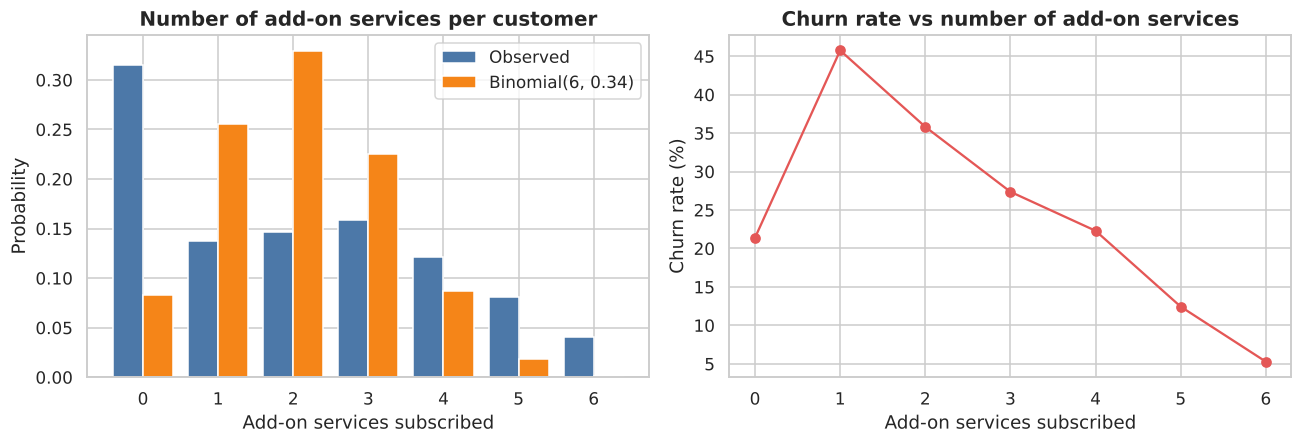

Chi-square GOF vs Binomial: chi2=14381.2, p=0.00e+00  -> rejects Binomial


In [15]:
# ---------- 6. Discrete probability distributions ----------
# (a) Churn ~ Bernoulli(p)   (b) number of add-on services (0-6) vs Binomial(6, p)
p_churn = RESULTS["churn_rate"]
print(f"Churn ~ Bernoulli(p = {p_churn:.3f});  Var = p(1-p) = {p_churn*(1-p_churn):.3f}")
addon = ["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
n_serv = (df[addon] == "Yes").sum(axis=1)
obs = n_serv.value_counts(normalize=True).sort_index()
p_hat = n_serv.mean() / 6
k = np.arange(0, 7); binom_pmf = stats.binom.pmf(k, 6, p_hat)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].bar(k - .2, obs.reindex(k, fill_value=0).values, width=.4, label="Observed", color="#4C78A8")
ax[0].bar(k + .2, binom_pmf, width=.4, label=f"Binomial(6, {p_hat:.2f})", color="#F58518")
ax[0].set(title="Number of add-on services per customer", xlabel="Add-on services subscribed", ylabel="Probability"); ax[0].legend()
chr_ = df.groupby(n_serv)["Churn"].apply(lambda s: (s == "Yes").mean())
ax[1].plot(chr_.index, chr_.values * 100, "o-", color="#E45756")
ax[1].set(title="Churn rate vs number of add-on services", xlabel="Add-on services subscribed", ylabel="Churn rate (%)")
savefig("10_discrete_distributions")
# chi-square goodness-of-fit (merge sparse tail so expected counts >= 5)
exp = binom_pmf * len(df); obs_c = n_serv.value_counts().reindex(k, fill_value=0).values
chi2, pv = stats.chisquare(obs_c, exp * obs_c.sum() / exp.sum())
print(f"Chi-square GOF vs Binomial: chi2={chi2:.1f}, p={pv:.2e}  -> {'rejects' if pv<.05 else 'does not reject'} Binomial")
RESULTS["binom"] = {"p_hat": float(p_hat), "chi2": float(chi2), "p": float(pv)}
RESULTS["churn_by_nservices"] = chr_.round(3).to_dict()


### Statistical analysis 2 - Discrete distributions
- **Churn** is a **Bernoulli(p = 0.265)** variable (variance p(1-p) = 0.195).
- **Number of add-on services (0-6)** was compared with a **Binomial(6, 0.34)** model. The chi-square goodness-of-fit test **rejects** the Binomial (p < 0.001): there are far more customers with **0 services** than expected (31%), mainly because the 1,526 customers *without internet* cannot buy any add-on, while the share declines gradually from 1 to 6 services (only about 4% take all six). So services are not independent coin-flips - customers behave in groups.
- **Churn vs number of services:** churn is highest for customers with only 1 add-on (45.8%) and falls steadily to **5.3% for customers with all 6** - each extra service makes the customer "stickier".

,feature,test,statistic,p_value,effect,significant
0,Contract,Chi-square,1184.6,5.86e-258,0.410,True
1,tenure,Mann-Whitney U,2515538.0,2.42e-208,-0.352,True
2,OnlineSecurity,Chi-square,850.0,2.66e-185,0.347,True
3,TechSupport,Chi-square,828.2,1.44e-180,0.343,True
4,InternetService,Chi-square,732.3,9.57e-160,0.322,True
5,PaymentMethod,Chi-square,648.1,3.68e-140,0.303,True
6,OnlineBackup,Chi-square,601.8,2.08e-131,0.292,True
7,DeviceProtection,Chi-square,558.4,5.51e-122,0.282,True
8,StreamingTV,Chi-square,374.2,5.53e-82,0.231,True
9,StreamingMovies,Chi-square,375.7,2.67e-82,0.231,True


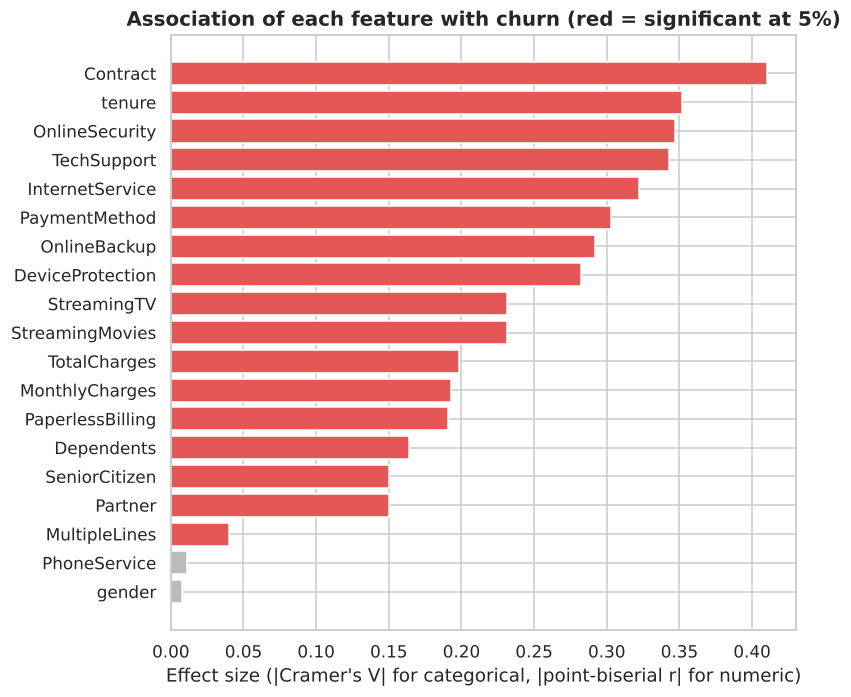

In [16]:
# ---------- 7. Bivariate / multivariate statistical tests ----------
# Numeric vs Churn: Mann-Whitney U (non-normal data) ; Categorical vs Churn: chi-square + Cramer's V
tests = []
for c in num_cols:
    u, p = stats.mannwhitneyu(df.loc[df.Churn == "Yes", c], df.loc[df.Churn == "No", c])
    tests.append({"feature": c, "test": "Mann-Whitney U", "statistic": round(u, 0), "p_value": p, "effect": round(float(stats.pointbiserialr((df.Churn=='Yes').astype(int), df[c])[0]), 3)})
for c in cat_cols:
    ct = pd.crosstab(df[c], df["Churn"]); chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    tests.append({"feature": c, "test": "Chi-square", "statistic": round(chi2, 1), "p_value": p, "effect": round(v, 3)})
tests = pd.DataFrame(tests).sort_values("effect", key=abs, ascending=False)
tests["significant"] = tests["p_value"] < .05
display(tests.assign(p_value=tests.p_value.map("{:.2e}".format)).reset_index(drop=True))
RESULTS["tests_top"] = tests.head(8).assign(p_value=tests.head(8).p_value.map("{:.2e}".format)).to_dict("records")
RESULTS["not_significant"] = tests.loc[~tests.significant, "feature"].tolist()

plt.figure(figsize=(7.5, 6.5))
tt = tests.sort_values("effect", key=abs)
plt.barh(tt["feature"], tt["effect"].abs(), color=["#E45756" if s else "#BBBBBB" for s in tt["significant"]])
plt.xlabel("Effect size (|Cramer's V| for categorical, |point-biserial r| for numeric)")
plt.title("Association of each feature with churn (red = significant at 5%)")
savefig("11_association_strength")


### Statistical analysis 3 - Bivariate tests
Numeric features vs churn used **Mann-Whitney U** (non-normal data); categorical features used the **chi-square test of independence** with **Cramer's V** as effect size.
- **17 of 19 features are significantly related to churn (p < 0.05).** Strongest: `Contract` (V = 0.41), `tenure` (r = -0.35), `OnlineSecurity` (0.35), `TechSupport` (0.34), `InternetService` (0.32), `PaymentMethod` (0.30).
- **`gender` (p = 0.49) and `PhoneService` (p = 0.34) are NOT significant** - these can be safely ignored; the company does not lose customers because of gender or just having a phone line.
- Interpretation: churn is driven by *contract commitment, tenure, support/security add-ons, internet type and payment method*, not by demographics.

In [17]:
# ---------- 8. Preprocessing: encoding, split, scaling ----------
data = df.drop(columns=["customerID"]).copy()
y = (data.pop("Churn") == "Yes").astype(int).values
# Binary Yes/No-style columns -> 0/1 ; multi-class columns -> one-hot
bin_cols = [c for c in cat_cols if data[c].nunique() == 2]
multi_cols = [c for c in cat_cols if data[c].nunique() > 2]
for c in bin_cols:
    vals = sorted(data[c].unique())
    pos = "Yes" if "Yes" in vals else ("Female" if "Female" in vals else vals[-1])
    data[c] = (data[c] == pos).astype(int)
X = pd.get_dummies(data, columns=multi_cols, drop_first=False).astype(float)
print("Binary-encoded:", bin_cols); print("One-hot encoded:", multi_cols)
print("Final feature matrix:", X.shape)

# 70 / 15 / 15 stratified split
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=.50, stratify=y_tmp, random_state=SEED)
# Standardise numeric columns using ONLY training statistics (avoids data leakage)
scaler = StandardScaler().fit(X_tr[num_cols])
for part in (X_tr, X_va, X_te): part.loc[:, num_cols] = scaler.transform(part[num_cols])
feature_names = list(X.columns)
print(f"Train {X_tr.shape} | Validation {X_va.shape} | Test {X_te.shape}")
print("Churn rate  train/val/test: %.3f / %.3f / %.3f" % (y_tr.mean(), y_va.mean(), y_te.mean()))
RESULTS["split"] = {"train": len(X_tr), "val": len(X_va), "test": len(X_te), "n_features": X.shape[1]}
X_tr, X_va, X_te = X_tr.values.astype("float32"), X_va.values.astype("float32"), X_te.values.astype("float32")


Binary-encoded: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
One-hot encoded: ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']
Final feature matrix: (7043, 40)
Train (4930, 40) | Validation (1056, 40) | Test (1057, 40)
Churn rate  train/val/test: 0.265 / 0.265 / 0.266


**Preprocessing summary.** `customerID` dropped (identifier). 6 binary columns encoded 0/1, 10 multi-category columns one-hot encoded (**40 features** in total). Stratified **70/15/15** train/validation/test split keeps the churn ratio identical (26.5%) in every part. Standardisation (`StandardScaler`) is fitted on the **training set only** to avoid data leakage.

In [18]:
# ---------- 9. Baseline model (Logistic Regression) for comparison ----------
lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_tr, y_tr)
lr_prob = lr.predict_proba(X_te)[:, 1]
RESULTS["baseline"] = {"auc": float(roc_auc_score(y_te, lr_prob)), "acc": float(accuracy_score(y_te, lr_prob > .5)),
                       "recall": float(recall_score(y_te, lr_prob > .5)), "f1": float(f1_score(y_te, lr_prob > .5))}
print("Logistic Regression baseline:", {k: round(v, 3) for k, v in RESULTS["baseline"].items()})


Logistic Regression baseline: {'auc': 0.845, 'acc': 0.747, 'recall': 0.779, 'f1': 0.621}


**Baseline.** A class-weighted Logistic Regression gives a test AUC of 0.845 - a reference to judge whether the deep model adds value.

## Deep Learning model - Multi-Layer Perceptron (MLP)
**Architecture:** Input (40) -> Dense(h1, ReLU) -> Dropout -> Dense(h2, ReLU) -> Dropout -> Dense(1, Sigmoid).
**Training set-up:** Adam optimizer, binary cross-entropy loss, batch size 64, up to 100 epochs with **early stopping** on validation AUC (patience 12, best weights restored), **class weights** to handle the 26.5/73.5 imbalance.
**Basic hyper-parameter tuning:** grid search over hidden sizes {(32,16), (64,32), (128,64)} x dropout {0.2, 0.4} x learning rate {0.001, 0.01} = 12 configurations, chosen by **validation AUC** (the test set is never used for tuning).

In [19]:
# ---------- 10. Deep Learning model: MLP + basic hyper-parameter tuning ----------
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_tr)
class_weight = {0: cw[0], 1: cw[1]}
print("Class weights:", {k: round(v, 2) for k, v in class_weight.items()})

def build_mlp(input_dim, units=(64, 32), dropout=0.3, lr=1e-3):
    m = keras.Sequential([layers.Input(shape=(input_dim,))])
    for u in units:
        m.add(layers.Dense(u, activation="relu", kernel_initializer="he_normal"))
        m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation="sigmoid"))
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m

def fit_model(units, dropout, lr, epochs=100, verbose=0):
    keras.utils.set_random_seed(SEED)
    m = build_mlp(X_tr.shape[1], units, dropout, lr)
    es = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=12, restore_best_weights=True)
    h = m.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=epochs, batch_size=64,
              class_weight=class_weight, callbacks=[es], verbose=verbose)
    return m, h

grid = [(u, d, l) for u in [(32, 16), (64, 32), (128, 64)] for d in [0.2, 0.4] for l in [1e-3, 1e-2]]
tune_rows = []
for units, drop, lr_ in grid:
    m, h = fit_model(units, drop, lr_)
    va_auc = roc_auc_score(y_va, m.predict(X_va, verbose=0).ravel())
    tune_rows.append({"hidden_units": str(units), "dropout": drop, "learning_rate": lr_,
                      "epochs_run": len(h.history["loss"]), "val_auc": round(va_auc, 4)})
    print(tune_rows[-1])
tune = pd.DataFrame(tune_rows).sort_values("val_auc", ascending=False).reset_index(drop=True)
display(tune)
best = grid[int(pd.DataFrame(tune_rows)["val_auc"].idxmax())]
print("\nBest config (by validation AUC):", best)
RESULTS["tuning"] = tune.to_dict("records"); RESULTS["best_cfg"] = {"units": list(best[0]), "dropout": best[1], "lr": best[2]}


Class weights: {0: np.float64(0.68), 1: np.float64(1.88)}


{'hidden_units': '(32, 16)', 'dropout': 0.2, 'learning_rate': 0.001, 'epochs_run': 30, 'val_auc': 0.8412}


{'hidden_units': '(32, 16)', 'dropout': 0.2, 'learning_rate': 0.01, 'epochs_run': 18, 'val_auc': 0.843}


{'hidden_units': '(32, 16)', 'dropout': 0.4, 'learning_rate': 0.001, 'epochs_run': 41, 'val_auc': 0.8417}


{'hidden_units': '(32, 16)', 'dropout': 0.4, 'learning_rate': 0.01, 'epochs_run': 22, 'val_auc': 0.8459}


...

{'hidden_units': '(128, 64)', 'dropout': 0.2, 'learning_rate': 0.01, 'epochs_run': 13, 'val_auc': 0.8443}


{'hidden_units': '(128, 64)', 'dropout': 0.4, 'learning_rate': 0.001, 'epochs_run': 26, 'val_auc': 0.8454}


{'hidden_units': '(128, 64)', 'dropout': 0.4, 'learning_rate': 0.01, 'epochs_run': 13, 'val_auc': 0.8456}


,hidden_units,dropout,learning_rate,epochs_run,val_auc
0,"(32, 16)",0.4,0.010,22,0.8459
1,"(128, 64)",0.2,0.001,20,0.8457
2,"(128, 64)",0.4,0.010,13,0.8456
3,"(128, 64)",0.4,0.001,26,0.8454
4,"(128, 64)",0.2,0.010,13,0.8443
5,"(64, 32)",0.2,0.001,22,0.8433
6,"(32, 16)",0.2,0.010,18,0.8430
7,"(64, 32)",0.2,0.010,15,0.8424
8,"(64, 32)",0.4,0.010,16,0.8424
9,"(32, 16)",0.4,0.001,41,0.8417



Best config (by validation AUC): ((32, 16), 0.4, 0.01)


**Tuning result.** All 12 configurations land within a narrow band (validation AUC 0.841-0.846), so the model is not very sensitive to these settings. The best was hidden layers **(32, 16), dropout 0.4, learning rate 0.01**.

In [20]:
# ---------- 11. Train final model with the best hyper-parameters ----------
model, hist = fit_model(*best, verbose=0)
model.summary()
RESULTS["epochs_trained"] = len(hist.history["loss"])
RESULTS["n_params"] = int(model.count_params())


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_36 (Dense)                │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,573 (21.77 KB)

 Trainable params: 1,857 (7.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,716 (14.52 KB)

The final model is small (about 1,900 trainable weights) - appropriate for 5,000 training rows; a bigger network gave no gain and would overfit.

MLP test metrics: {'auc': 0.839, 'acc': 0.746, 'precision': 0.516, 'recall': 0.762, 'f1': 0.615}
              precision    recall  f1-score   support

    No churn       0.90      0.74      0.81       776
       Churn       0.52      0.76      0.61       281

    accuracy                           0.75      1057
   macro avg       0.71      0.75      0.71      1057
weighted avg       0.79      0.75      0.76      1057



,auc,acc,recall,f1
Logistic Regression,0.845,0.747,0.779,0.621
MLP (tuned),0.839,0.746,0.762,0.615


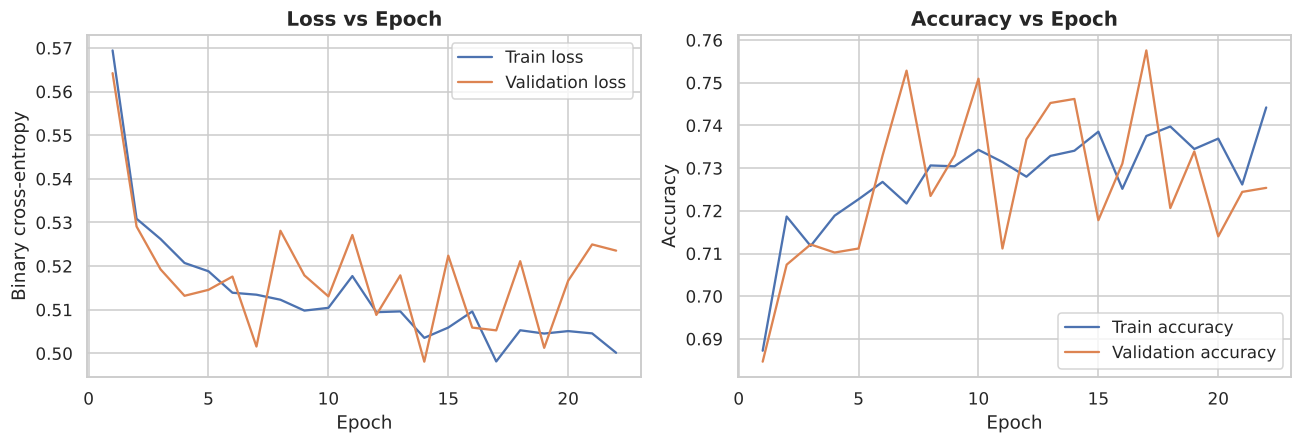

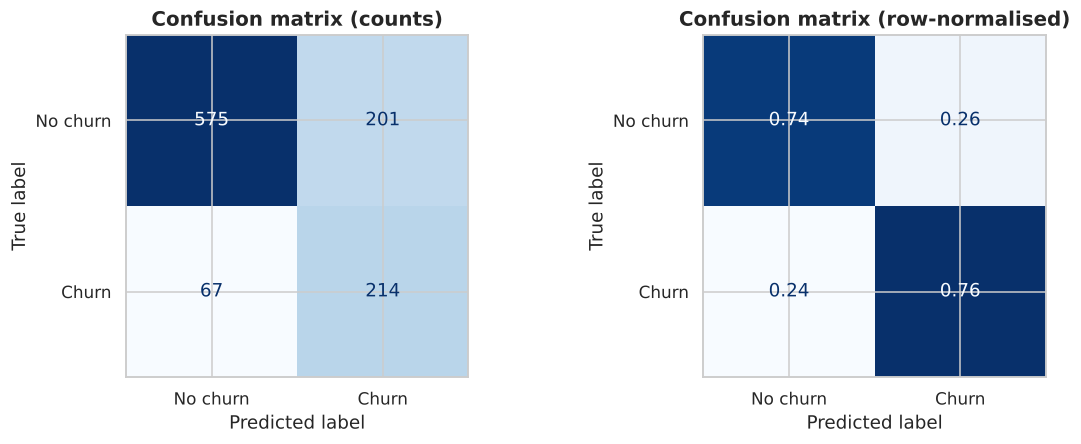

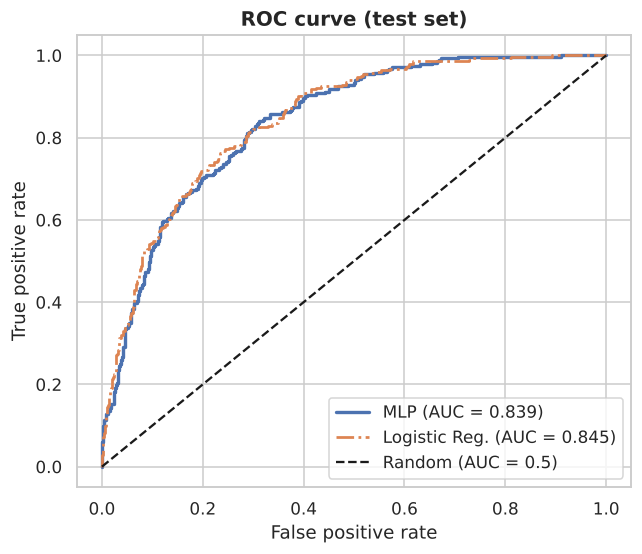

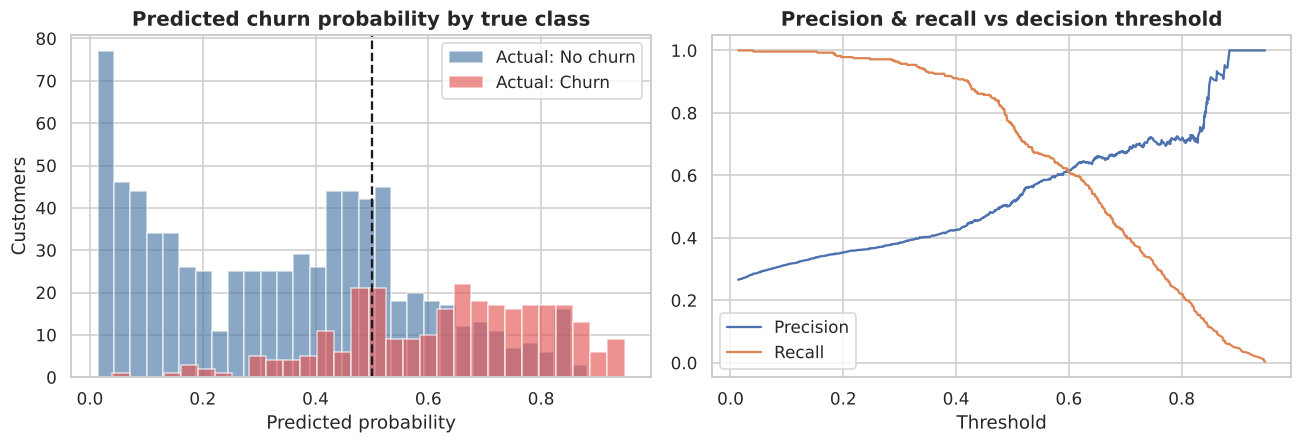

In [21]:
# ---------- 12. Evaluation on the held-out TEST set ----------
prob = model.predict(X_te, verbose=0).ravel()
pred = (prob >= 0.5).astype(int)
metrics = {"auc": roc_auc_score(y_te, prob), "acc": accuracy_score(y_te, pred), "precision": precision_score(y_te, pred),
           "recall": recall_score(y_te, pred), "f1": f1_score(y_te, pred)}
RESULTS["mlp"] = {k: float(v) for k, v in metrics.items()}
print("MLP test metrics:", {k: round(v, 3) for k, v in metrics.items()})
print(classification_report(y_te, pred, target_names=["No churn", "Churn"]))
cmp = pd.DataFrame({"Logistic Regression": RESULTS["baseline"], "MLP (tuned)": RESULTS["mlp"]}).T[["auc", "acc", "recall", "f1"]].round(3)
display(cmp)

# Chart A+B: loss & accuracy vs epoch
ep = range(1, len(hist.history["loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(ep, hist.history["loss"], label="Train loss"); ax[0].plot(ep, hist.history["val_loss"], label="Validation loss")
ax[0].set(title="Loss vs Epoch", xlabel="Epoch", ylabel="Binary cross-entropy"); ax[0].legend()
ax[1].plot(ep, hist.history["accuracy"], label="Train accuracy"); ax[1].plot(ep, hist.history["val_accuracy"], label="Validation accuracy")
ax[1].set(title="Accuracy vs Epoch", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend()
savefig("12_loss_accuracy_vs_epoch")

# Chart C: confusion matrix
cm = confusion_matrix(y_te, pred); RESULTS["cm"] = cm.tolist()
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay(confusion_matrix(y_te, pred, normalize="true"), display_labels=["No churn", "Churn"]).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f")
ax[1].set_title("Confusion matrix (row-normalised)")
savefig("13_confusion_matrix")

# Chart D: ROC curve (MLP vs baseline)
fpr, tpr, _ = roc_curve(y_te, prob); fpr2, tpr2, _ = roc_curve(y_te, lr_prob)
plt.figure(figsize=(6, 5.2))
plt.plot(fpr, tpr, lw=2.2, label=f"MLP (AUC = {metrics['auc']:.3f})")
plt.plot(fpr2, tpr2, lw=1.8, ls="-.", label=f"Logistic Reg. (AUC = {RESULTS['baseline']['auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.5)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curve (test set)"); plt.legend(loc="lower right")
savefig("14_roc_curve")

# Chart E: predicted probability distribution + precision/recall vs threshold
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(prob[y_te == 0], bins=30, alpha=.65, label="Actual: No churn", color="#4C78A8")
ax[0].hist(prob[y_te == 1], bins=30, alpha=.65, label="Actual: Churn", color="#E45756")
ax[0].axvline(.5, color="k", ls="--"); ax[0].set(title="Predicted churn probability by true class", xlabel="Predicted probability", ylabel="Customers"); ax[0].legend()
pr, rc, th = precision_recall_curve(y_te, prob)
ax[1].plot(th, pr[:-1], label="Precision"); ax[1].plot(th, rc[:-1], label="Recall")
ax[1].set(title="Precision & recall vs decision threshold", xlabel="Threshold"); ax[1].legend()
savefig("15_probability_and_threshold")


## Model evaluation (held-out test set, 1,057 customers)

### Chart 1 & 2 - Loss vs epoch and accuracy vs epoch
- **Conveys:** how the model learns over time. Training and validation loss drop together quickly in the first ~5 epochs and then flatten at about 0.50-0.52; the two curves stay close, so there is **no serious overfitting**. Validation curves are noisy because the validation set is small (1,056 rows) and early stopping restores the best epoch.

### Chart 3 - Confusion matrix
- **Conveys:** the errors by type. Of 281 real churners the model catches **214 (recall 76%)** and misses 67; of 776 loyal customers it correctly clears 575 but wrongly flags 201 (precision for churn is 52%). For a retention campaign, missing a churner is usually costlier than sending a discount to a loyal customer, so the high recall is a deliberate, useful trade-off.

### Chart 4 - ROC curve and AUC
- **Conveys:** ranking quality across all thresholds. **AUC = 0.839** (0.5 = random, 1 = perfect), i.e. a randomly chosen churner gets a higher risk score than a randomly chosen loyal customer 84% of the time. The Logistic Regression baseline (0.845) is practically identical.

### Chart 5 - Probability distribution and precision/recall vs threshold
- **Conveys:** churners (red) receive mostly high probabilities and loyal customers (blue) low ones, with an overlap zone around 0.4-0.6. The threshold chart shows the business can **trade precision for recall** by moving the cut-off from 0.5.

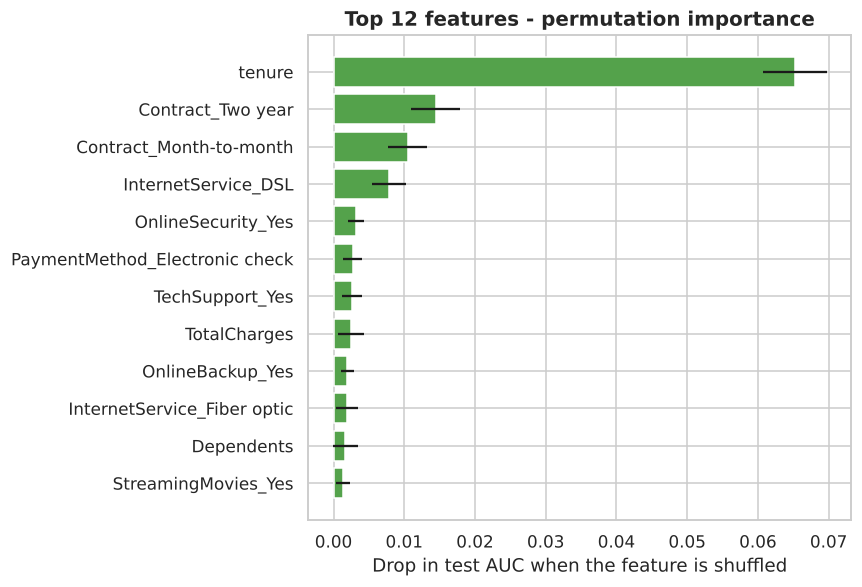

,feature,auc_drop,std
4,tenure,0.0652,0.0045
35,Contract_Two year,0.0144,0.0034
33,Contract_Month-to-month,0.0105,0.0028
12,InternetService_DSL,0.0078,0.0024
17,OnlineSecurity_Yes,0.0031,0.0011
38,PaymentMethod_Electronic check,0.0027,0.0014
26,TechSupport_Yes,0.0026,0.0014
8,TotalCharges,0.0025,0.0019
20,OnlineBackup_Yes,0.0019,0.0009
13,InternetService_Fiber optic,0.0019,0.0016


In [22]:
# ---------- 13. Feature importance (permutation importance on the test set, measured by AUC drop) ----------
rng = np.random.RandomState(SEED); base_auc = metrics["auc"]; imp = []
for j, name in enumerate(feature_names):
    drops = []
    for _ in range(10):
        Xp = X_te.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
        drops.append(base_auc - roc_auc_score(y_te, model.predict(Xp, verbose=0, batch_size=2048).ravel()))
    imp.append((name, np.mean(drops), np.std(drops)))
imp = pd.DataFrame(imp, columns=["feature", "auc_drop", "std"]).sort_values("auc_drop", ascending=False)
top = imp.head(12).iloc[::-1]
plt.figure(figsize=(8, 5.5))
plt.barh(top["feature"], top["auc_drop"], xerr=top["std"], color="#54A24B")
plt.xlabel("Drop in test AUC when the feature is shuffled"); plt.title("Top 12 features - permutation importance")
savefig("16_feature_importance")
display(imp.head(10).round(4))
RESULTS["importance_top"] = imp.head(8).round(4)[["feature", "auc_drop"]].to_dict("records")


### Feature analysis - permutation importance
**What:** shuffle one feature at a time on the test set and measure how much AUC drops. **Insight:** `tenure` dominates (AUC drops by 0.065, about 4-5x any other feature), followed by `Contract` type (two-year / month-to-month) and `InternetService` (DSL / fibre). This agrees with the EDA and statistical tests - the model learned the same drivers the analysis found, which makes the model trustworthy.

In [23]:
# ---------- 14. Save model & results ----------
os.makedirs("model", exist_ok=True)
model.save("model/churn_mlp.keras")
json.dump(RESULTS, open("results.json", "w"), indent=2, default=float)
print("Saved model/churn_mlp.keras and results.json")


Saved model/churn_mlp.keras and results.json


## Conclusion
- **Key findings:** churn (26.5%) is driven by *short tenure, month-to-month contracts, fibre-optic internet, electronic-check payment, no security/support add-ons* and higher monthly bills; gender and phone service do not matter.
- **Model:** the tuned MLP reaches **AUC 0.839, accuracy 74.6%, recall 76.2%, F1 0.615** on unseen data. It performs about the same as Logistic Regression (AUC 0.845): the relationships in this tabular data are mostly simple/linear, so extra depth gives no real gain - an honest and common result.
- **Challenges:** class imbalance, hidden missing values in `TotalCharges`, strongly correlated features, and small validation set noise.
- **Future scope:** try gradient boosting (XGBoost/LightGBM) and SMOTE/focal loss; tune the decision threshold using real cost of churn vs cost of a retention offer; add behavioural data (call-centre complaints, usage trends); use SHAP for per-customer explanations; deploy as an API/dashboard.